In [1]:
import numpy as np
from abc import ABC, abstractmethod
# Inicializamos la clase abstracta Layer, que tiene los métodos forward y backward que se implementarán en classes Lineal y Relu
class Layer(ABC):
    

    @abstractmethod
    def forward(batch_input):
        pass

    @abstractmethod
    def backward(error):
        pass


  


In [ ]:
#Inicialitzamos la clase Lineal y Relu, que hereda de Layer. Esta clase implementará los métodos forward y backward

class Lineal(Layer):
    def __init__(self, input_size, batch_size):
        self.w = np.random.randn(input_size, batch_size) 
        self.b = np.random.randn(1, batch_size)           

    def forward(self, x):
        return x @ self.w + self.b

    #Este metodo calcula la pèrdida restando la prediccion de la true, y devuelve la media de los errores al cuadrado
    def loss(spasself, y_pred, y_true):

        return np.mean((y_pred - y_true) ** 2)
    
    def backward(self, error):
        return error * self.w

class Relu(Layer):
    def __init__(self, input_size, batch_size):
            self.x = np.random.randn(input_size, batch_size) 
            self.b = np.random.randn(1, batch_size)           
    
    def forward(self, x):
        return np.maximum(0, x @ self.x + self.b)
    
    def backward(self, error):
        return error * (self.x > 0)  

In [1]:
import idx2numpy    
import matplotlib.pyplot as plt
file = 'data/Original dataset/train-images.idx3-ubyte'
arr = idx2numpy.convert_from_file(file)
image = np.asarray(arr[2]).squeeze()
plt.imshow(image)
plt.show()

ModuleNotFoundError: No module named 'idx2numpy'

Dataset: (60000, 28, 28) uint8


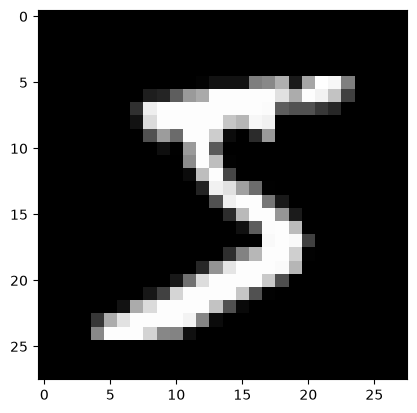

Batch: (64, 784)
Capa1 Lineal: (64, 784) -> (64, 128)
Capa2 Relu:   (64, 128) -> (64, 64)
Capa3 Lineal: (64, 64) -> (64, 10)


In [7]:
import idx2numpy
import matplotlib.pyplot as plt

file = 'data/Original dataset/train-images.idx3-ubyte'
arr = idx2numpy.convert_from_file(file)
print("Dataset:", arr.shape, arr.dtype)        # (60000, 28, 28) uint8

# Ver una imagen
plt.imshow(arr[0], cmap='gray')
plt.show()

# Preparar un batch: aplanar y normalizar
np.random.seed(0)
n = 64
x = arr[:n].reshape(n, -1).astype(np.float64) / 255.0
print("Batch:", x.shape)                        # (64, 784)

# Red: 784 -> 128 -> 64 -> 10
capa1 = Lineal(784, 128)
capa2 = Relu(128, 64)
capa3 = Lineal(64, 10)

h1 = capa1.forward(x)
h2 = capa2.forward(h1)
out = capa3.forward(h2)

print("Capa1 Lineal:", x.shape, "->", h1.shape)    # (64, 784) -> (64, 128)
print("Capa2 Relu:  ", h1.shape, "->", h2.shape)   # (64, 128) -> (64, 64)
print("Capa3 Lineal:", h2.shape, "->", out.shape)  # (64, 64)  -> (64, 10)
